PREPARE WORKSPACE:

In [1]:
# SET HYPERPARAMETERS

In [2]:
# IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# LOAD DATA

account_info = pd.read_csv("account_info.csv")
user_activity = pd.read_csv("user_activity.csv")

DATA VALIDATION:

In [4]:
# INSPECT DATA 'account_info'

"""
print(account_info.isna().sum())
print(account_info.dtypes)
print(account_info["customer_id"])
print(account_info["plan_list_price"].value_counts())
print(account_info)
print(account_info["plan"].value_counts())
print(account_info["churn_status"].value_counts())
"""

'\nprint(account_info.isna().sum())\nprint(account_info.dtypes)\nprint(account_info["customer_id"])\nprint(account_info["plan_list_price"].value_counts())\nprint(account_info)\nprint(account_info["plan"].value_counts())\nprint(account_info["churn_status"].value_counts())\n'

In [5]:
# INSPECT DATA 'user_activity'

"""
print(user_activity)
print(user_activity.isna().sum())
print(user_activity.dtypes)
print(pd.to_datetime(user_activity["event_time"]))


"""

'\nprint(user_activity)\nprint(user_activity.isna().sum())\nprint(user_activity.dtypes)\nprint(pd.to_datetime(user_activity["event_time"]))\n\n\n'

In [6]:
# ADJUST DATA

# ACCOUNT INFO
# Create "user_id" column in 'account_info' dataset
account_info["user_id"] = pd.to_numeric(account_info["customer_id"].str.replace(r"\D", "", regex=True))
# Create boolean variable "churn"
account_info["churn_status"] = account_info["churn_status"].eq("Y")
# Set logical order of subscription plans and transform to categorical instead of string
plan_order = ["Free", "Basic", "Pro", "Enterprise"]
account_info["plan"] = pd.Categorical(
    account_info["plan"],
    categories=plan_order,
    ordered=True)

# USER ACTIVITY
# Transform time into correct format
user_activity["event_time"] = pd.to_datetime(user_activity["event_time"])

# CUSTOMER SUPPORT


# JOINED OPERATIONS
# For each user obtain number of unique days he was active
active_days = (# Count distinct active days for each user
    user_activity
    .assign(activity_date=user_activity["event_time"].dt.date)
    .groupby("user_id")["activity_date"]
    .nunique()
    .rename("active_days"))
account_info = account_info.merge(# Add active_days to account_info
    active_days,
    on="user_id",
    how="left")
account_info["active_days"] = account_info["active_days"].fillna(0).astype(int)# Users with no activity get 0 active days



EXPLORATORY DATA ANALYSIS:

In [7]:
### 3 PLOTS OF 1 VARIABLE

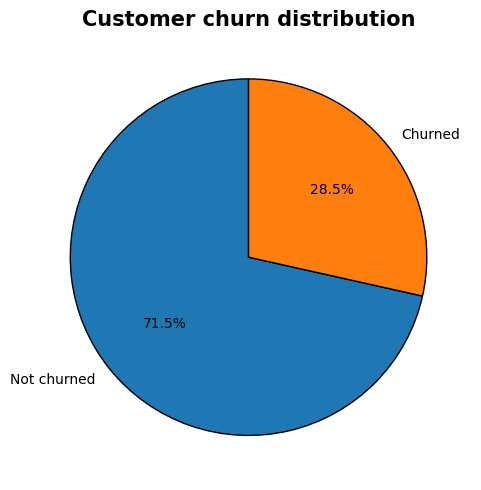

In [8]:
# PLOT 1: DISTRIBUTION OF CHURN

counts = (
    account_info["churn_status"]
    .value_counts()
    .reindex([False, True], fill_value=0)
)

labels = ["Not churned", "Churned"]

plt.figure(figsize=(7, 5))

plt.pie(
    counts.values,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "black"}
)

plt.title(
    "Customer churn distribution",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig("plot11.png", bbox_inches="tight", dpi=300)
plt.show()

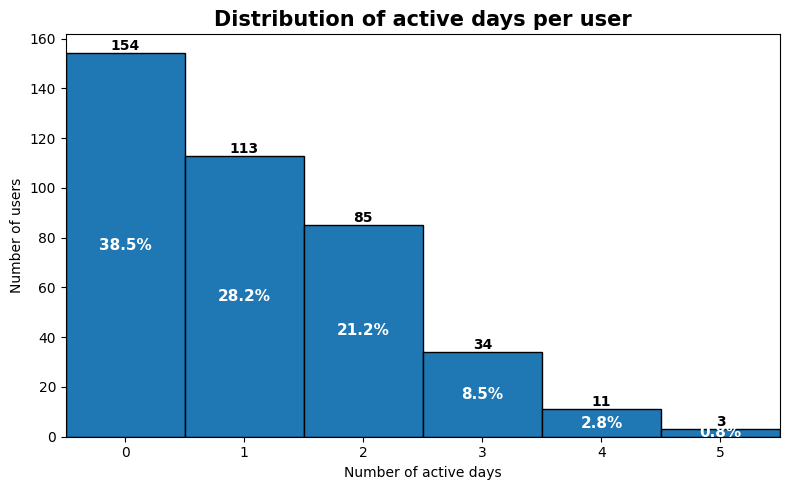

In [9]:
# PLOT 2: DISTRIBUTION OF THE COUNT OF DISTINCT DAYS USERS ARE ACTIVE

data = account_info["active_days"]

total = len(data)

plt.figure(figsize=(8, 5))

# One bin centered on each integer: 0, 1, 2, 3, 4, 5
bins = [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5, 5.5]

counts, edges, patches = plt.hist(
    data,
    bins=bins,
    edgecolor="black"
)

for count, patch in zip(counts, patches):
    if count > 0:
        percentage = count / total * 100

        # Percentage inside the bar
        plt.text(
            patch.get_x() + patch.get_width() / 2,
            patch.get_height() / 2,
            f"{percentage:.1f}%",
            ha="center",
            va="center",
            color="white",
            fontsize=11,
            fontweight="bold"
        )

        # Absolute count above the bar
        plt.text(
            patch.get_x() + patch.get_width() / 2,
            patch.get_height(),
            f"{int(count)}",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold"
        )

plt.title("Distribution of active days per user", fontsize=15, fontweight="bold")
plt.xlabel("Number of active days")
plt.ylabel("Number of users")
plt.xticks(range(6))
plt.xlim(-0.5, 5.5)

plt.tight_layout()
plt.savefig("plot12.png", bbox_inches="tight", dpi=300)
plt.show()

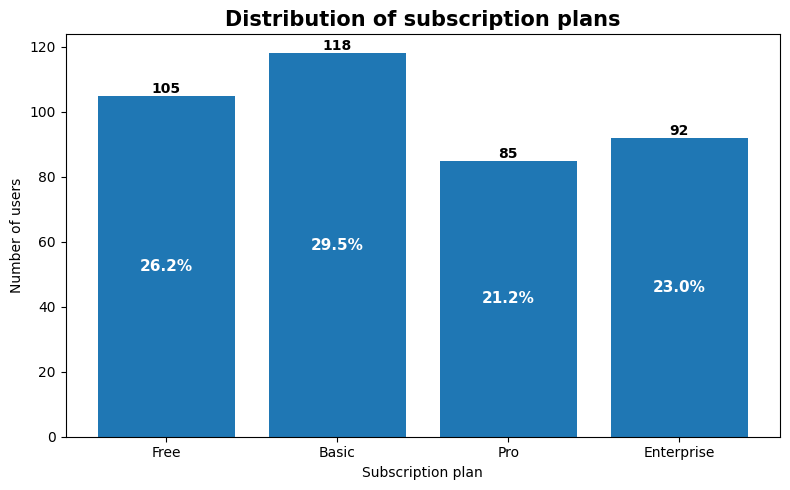

In [10]:
# PLOT 3: DISTRIBUTION OF 'plans'

plan_counts = account_info["plan"].value_counts(sort=False)

plt.figure(figsize=(8, 5))

bars = plt.bar(plan_counts.index, plan_counts.values)

total = plan_counts.sum()

for bar, count in zip(bars, plan_counts.values):
    percentage = count / total * 100

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() / 2,
        f"{percentage:.1f}%",
        ha="center",
        va="center",
        color="white",
        fontsize=11,
        fontweight="bold"
    )

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(count)}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.title("Distribution of subscription plans", fontsize=15, fontweight="bold")
plt.xlabel("Subscription plan")
plt.ylabel("Number of users")
plt.tight_layout()
plt.savefig("plot13.png", bbox_inches="tight", dpi=300)
plt.show()

In [11]:
### 2 PLOTS OF 2 VARIABLES

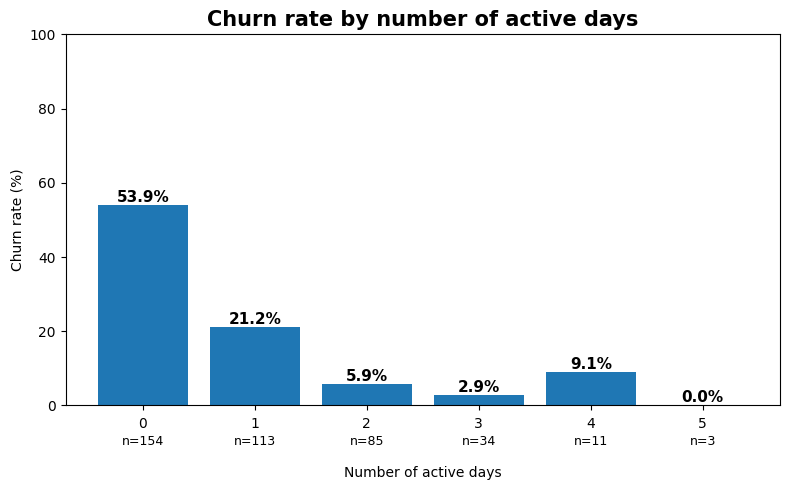

In [12]:
# PLOT 1: DISTRIBUTION OF 'churn' AGAINST NUMBER OF ACTIVE DAYS

churn_by_activity = (
    account_info
    .groupby("active_days")["churn_status"]
    .agg(["mean", "count"])
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    churn_by_activity.index,
    churn_by_activity["mean"] * 100
)

for bar, rate, count in zip(
    bars,
    churn_by_activity["mean"],
    churn_by_activity["count"]
):
    # Churn rate above the bar
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{rate * 100:.1f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

    # Group size below the x-axis
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        -0.08,
        f"n={count}",
        transform=plt.gca().get_xaxis_transform(),
        ha="center",
        va="top",
        fontsize=9
    )

plt.title("Churn rate by number of active days", fontsize=15, fontweight="bold")
plt.xlabel("Number of active days", labelpad=25)
plt.ylabel("Churn rate (%)")

# Move x-axis tick labels down
plt.tick_params(axis="x", pad=5)

plt.xticks(churn_by_activity.index)

plt.ylim(0, 100)
plt.tight_layout()
plt.savefig("plot21.png", bbox_inches="tight", dpi=300)
plt.show()

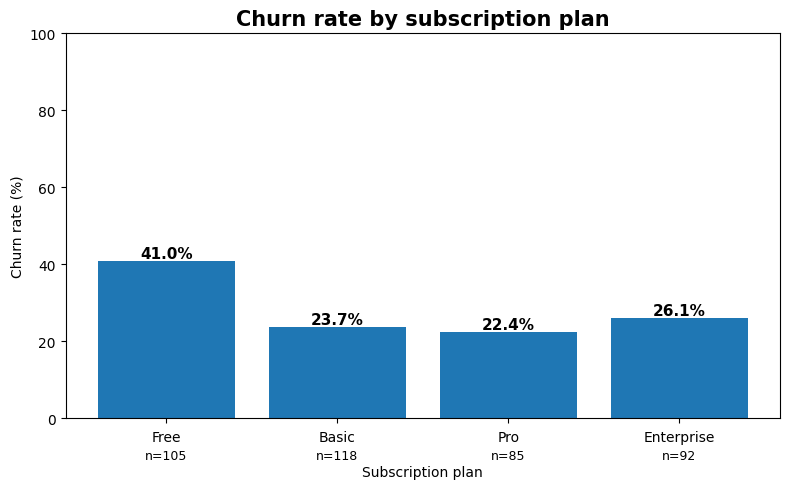

In [13]:
# PLOT 2: DISTRIBUTION OF 'churn' AGAINST 'plan'

# Calculate churn rate and group size for each plan
churn_by_plan = (
    account_info
    .groupby("plan")["churn_status"]
    .agg(["mean", "count"])
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    churn_by_plan.index,
    churn_by_plan["mean"] * 100
)

for bar, rate, count in zip(
    bars,
    churn_by_plan["mean"],
    churn_by_plan["count"]
):
    # Churn rate above the bar
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{rate * 100:.1f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

    # Group size below the x-axis
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        -0.08,
        f"n={count}",
        transform=plt.gca().get_xaxis_transform(),
        ha="center",
        va="top",
        fontsize=9
    )

plt.title("Churn rate by subscription plan", fontsize=15, fontweight="bold")
plt.xlabel("Subscription plan", labelpad=15)
plt.ylabel("Churn rate (%)")

# Keep category labels close to the axis
plt.tick_params(axis="x", pad=5)

# Leave space above the highest bar for percentage labels
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig("plot22.png", bbox_inches="tight", dpi=300)
plt.show()

BUSINESS METRICS:

In [14]:
observation_days = (
    user_activity["event_time"].max() -
    user_activity["event_time"].min()
).days + 1

account_info["active_days_180d_equivalent"] = (
    account_info["active_days"] / observation_days * 180
)

low_engagement_rate = (
    account_info["active_days_180d_equivalent"] <= 1
).mean()

print(low_engagement_rate)

0.6675
